# 03 · Lateness vs. review scores

**Question:** How much lower are review scores for late orders than for
on-time orders, and does the gap grow the later an order arrives?

Source: the `order_outcomes` view (`sql/02_order_outcomes.sql`): delivered
orders bought Jan 2017 - Aug 2018, latest review per order. Orders without a
review are excluded.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# Notebooks run from notebooks/, so add src/ to the import path.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from db import query

sns.set_theme(style="whitegrid")

In [2]:
reviews = query("""
    SELECT order_id, review_score, is_late, days_late, review_before_delivery,
           customer_state, purchase_month::text AS purchase_month
    FROM order_outcomes
    WHERE review_score IS NOT NULL
""")
print(f"{len(reviews):,} reviewed orders")

95,560 reviewed orders


## 1. Late vs. on-time

**Question:** What is the average review score for late and on-time orders,
and how sure are we of each average (95% confidence interval)?

In [3]:
summary = (reviews.groupby("is_late")["review_score"]
           .agg(orders="count", mean_score="mean", std="std"))
summary["ci_low"] = summary["mean_score"] - 1.96 * summary["std"] / np.sqrt(summary["orders"]) # confidence interval lower bound
summary["ci_high"] = summary["mean_score"] + 1.96 * summary["std"] / np.sqrt(summary["orders"]) # confidence interval upper bound
summary["pct_1_star"] = reviews.groupby("is_late")["review_score"].apply(lambda s: 100 * (s == 1).mean())
summary["pct_5_star"] = reviews.groupby("is_late")["review_score"].apply(lambda s: 100 * (s == 5).mean())
summary.drop(columns="std").round(2)

,orders,mean_score,ci_low,ci_high,pct_1_star,pct_5_star
is_late,,,,,,
False,89182,4.29,4.28,4.30,6.60,62.28
True,6378,2.27,2.23,2.31,53.76,16.54


**Observations:**

- Late orders average 2.27 stars vs 4.29 for on-time orders, a gap of about 2 stars (4.29 − 2.27 = 2.02).
- The 95% CIs don't overlap (late 2.23–2.31, on-time 4.28–4.30), so the gap is not random noise.
- Late orders got 1 star 53.8% of the time vs 6.6% for on-time orders (about 8× more; 53.76 / 6.60 ≈ 8.1).
- 5-star reviews fall from 62.3% to 16.5%.
- The late group is small (6,378 vs 89,182) but still large enough for a tight CI.

## 2. Score distribution

**Question:** How are the 1-5 stars spread for late vs. on-time orders?
Does lateness shift every score down a little, or mainly create 1-star reviews?

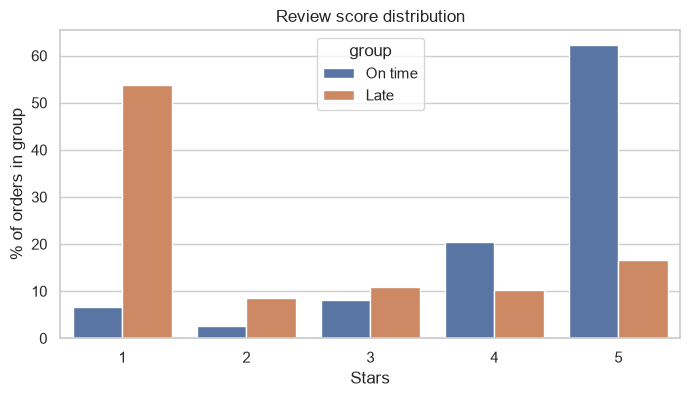

group,Late,On time
review_score,,
1,53.8,6.6
2,8.7,2.6
3,10.9,8.1
4,10.2,20.4
5,16.5,62.3


In [4]:
dist = (reviews.groupby("is_late")["review_score"]
        .value_counts(normalize=True).mul(100).rename("pct").reset_index())
dist["group"] = dist["is_late"].map({False: "On time", True: "Late"})

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=dist, x="review_score", y="pct", hue="group", ax=ax)
ax.set(title="Review score distribution", xlabel="Stars", ylabel="% of orders in group")
plt.show()
dist.pivot(index="review_score", columns="group", values="pct").round(1)

**Observations:**

- On-time reviews are mostly 5 stars (62.3%). Late reviews are mostly 1 star (53.8%).
- Lateness doesn't shift every score down a little. It mainly turns 4–5 star reviews into 1-star reviews: 4+5 stars falls from 82.7% to 26.7%, and 1 star rises from 6.6% to 53.8%.

## 3. Score by days late

**Question:** Does the score drop gradually as an order gets later, or is
there a sharp break at the promised date? Includes early orders, to see
whether arriving *less early* already costs stars.

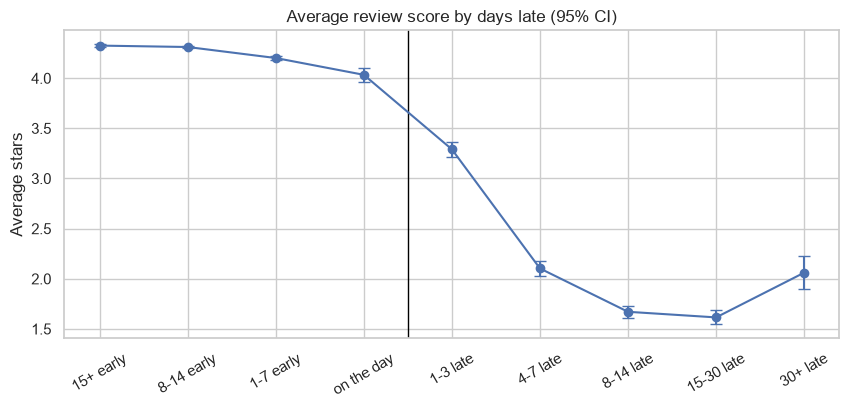

,orders,mean_score,ci
days_late_group,,,
15+ early,34526,4.32,0.01
8-14 early,36147,4.31,0.01
1-7 early,17229,4.20,0.02
on the day,1280,4.03,0.07
1-3 late,1851,3.29,0.07
4-7 late,1748,2.10,0.07
8-14 late,1446,1.67,0.06
15-30 late,1005,1.61,0.07
30+ late,328,2.06,0.17


In [5]:
bins   = [-np.inf, -15, -8, -1, 0, 3, 7, 14, 30, np.inf]
labels = ["15+ early", "8-14 early", "1-7 early", "on the day",
          "1-3 late", "4-7 late", "8-14 late", "15-30 late", "30+ late"]
reviews["days_late_group"] = pd.cut(reviews["days_late"], bins=bins, labels=labels)

by_days = (reviews.groupby("days_late_group", observed=True)["review_score"]
           .agg(orders="count", mean_score="mean", std="std"))
by_days["ci"] = 1.96 * by_days["std"] / np.sqrt(by_days["orders"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(by_days.index.astype(str), by_days["mean_score"], yerr=by_days["ci"],
            marker="o", capsize=4)
ax.axvline(3.5, color="black", linewidth=1)   # between "on the day" and "1-3 late"
ax.set(title="Average review score by days late (95% CI)", xlabel="", ylabel="Average stars")
plt.xticks(rotation=30)
plt.show()
by_days.drop(columns="std").round(2)

**Observations:**

- Scores are flat for orders 8+ days early (~4.31–4.32), then start slipping as orders arrive closer to the promised date: 4.20 for 1–7 days early, 4.03 on the day.
- The biggest drop comes right after the promised date: 4.03 on the day → 3.29 at 1–3 days late → 2.10 at 4–7 days late.
- Scores bottom out around 1.6 stars at 8–30 days late.
- The 30+ days late group ticks back up to 2.06, but it's small (328 orders, CI ±0.17). This is likely noise, not a real recovery.

## 4. Adjusted for state and month

**Why adjust:** notebook 02 showed late orders are concentrated in some
**states** (Northeast) and **months** (Nov 2017, Feb-Mar 2018). If those
states or months differ in this outcome anyway, the simple comparison above
mixes that in with the effect of lateness.

The regression below compares late and on-time orders **within the same
state and purchase month**. `is_late` is the number to read: the difference
associated with being late after that adjustment. `HC1` gives robust
standard errors (no assumption that the spread is equal across groups).

This is still an **association, not proof of cause**: anything else that
differs between late and on-time orders (product type, seller, price) is
not adjusted for here.

In [6]:
raw_gap = summary.loc[True, "mean_score"] - summary.loc[False, "mean_score"]

model = smf.ols("review_score ~ is_late + C(customer_state) + C(purchase_month)",
                data=reviews.assign(is_late=reviews["is_late"].astype(int))
               ).fit(cov_type="HC1")

adjusted = model.params["is_late"]
ci_low, ci_high = model.conf_int().loc["is_late"]
print(f"Raw gap (late - on time):      {raw_gap:+.2f} stars")
print(f"Adjusted gap (same state+month): {adjusted:+.2f} stars  (95% CI {ci_low:+.2f} to {ci_high:+.2f})")

Raw gap (late - on time):      -2.02 stars
Adjusted gap (same state+month): -1.96 stars  (95% CI -2.00 to -1.92)


**Observations:**

- Raw gap: −2.02 stars. Comparing late and on-time orders in the same state and month: −1.96 stars (95% CI −2.00 to −1.92).
- The gap barely changes (2.02 → 1.96), so state and month explain very little of it.
- This is still an association: product, seller and price are not adjusted for.

## 5. Robustness: reviews written after arrival only

**Question:** Some reviews were written *before* the order arrived (often a
customer still waiting). Does the gap hold when we keep only reviews written
on or after the delivery date?

In [7]:
after = reviews[~reviews["review_before_delivery"].astype(bool)]
print(f"Reviews written before delivery: {len(reviews) - len(after):,} "
      f"({100 * (1 - len(after) / len(reviews)):.1f}%)")

after_means = after.groupby("is_late")["review_score"].agg(orders="count", mean_score="mean", std="std")
after_means["ci_low"] = after_means["mean_score"] - 1.96 * after_means["std"] / np.sqrt(after_means["orders"])
after_means["ci_high"] = after_means["mean_score"] + 1.96 * after_means["std"] / np.sqrt(after_means["orders"])
print(after_means.drop(columns="std").round(2))

# CI for the gap itself: standard error of a difference = sqrt(se_late^2 + se_on_time^2)
gap = after_means.loc[True, "mean_score"] - after_means.loc[False, "mean_score"]
gap_se = np.sqrt((after_means["std"] ** 2 / after_means["orders"]).sum())
print(f"Gap using only after-arrival reviews: {gap:+.2f} stars "
      f"(95% CI {gap - 1.96 * gap_se:+.2f} to {gap + 1.96 * gap_se:+.2f})")

Reviews written before delivery: 4,970 (5.2%)
         orders  mean_score  ci_low  ci_high
is_late                                     
False     88961        4.29    4.28      4.3
True       1629        3.53    3.45      3.6
Gap using only after-arrival reviews: -0.77 stars (95% CI -0.84 to -0.69)


**Observations:**

- 4,970 reviews (5.2%) were written before the order arrived.
- Almost all of them are late orders: 4,749 of 6,378 late reviews were written before arrival (6,378 − 1,629 = 4,749), compared with only 221 on-time ones (89,182 − 88,961).
- Using only reviews written after arrival, the gap shrinks from −2.02 to −0.77 stars (95% CI −0.84 to −0.69; late 3.53 vs on-time 4.29).
- So a large part of the 2-star gap likely comes from customers reviewing while still waiting. Even after arrival, late orders still score lower.
- The late group is now small (1,629 orders), but the CI stays well below zero, so the after-arrival gap is not random noise.

## Decisions from this notebook

- Report both effects of lateness on reviews:
   - Total gap: −2.02 stars, which includes reviews written while customers were still waiting (the inconvenience of the delay).
   - After-delivery gap: −0.77 stars (95% CI −0.84 to −0.69), from reviews written once the order arrived (satisfaction after receiving it late).
- Most of the total gap comes from reviews written during the wait.